# YouTube Trending Video Views Prediction Using Machine Learning

In [6]:
%pip install pandas numpy matplotlib seaborn scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import glob
import json
import warnings

warnings.filterwarnings("ignore")

In [8]:
data_path = "../data/raw"

print("Dataset Path:", data_path)

Dataset Path: ../data/youtube


In [9]:
csv_files = glob.glob(
    os.path.join(data_path, "*videos.csv")
)

print("Number of CSV files found:", len(csv_files))

for file in csv_files:
    print(os.path.basename(file))

Number of CSV files found: 10
CAvideos.csv
DEvideos.csv
FRvideos.csv
GBvideos.csv
INvideos.csv
JPvideos.csv
KRvideos.csv
MXvideos.csv
RUvideos.csv
USvideos.csv


In [10]:
json_files = glob.glob(
    os.path.join(data_path, "*_category_id.json")
)

print("Number of JSON files found:", len(json_files))

for file in json_files:
    print(os.path.basename(file))

Number of JSON files found: 10
CA_category_id.json
DE_category_id.json
FR_category_id.json
GB_category_id.json
IN_category_id.json
JP_category_id.json
KR_category_id.json
MX_category_id.json
RU_category_id.json
US_category_id.json


In [11]:
print(f"CSV Files Found: {len(csv_files)}")
print(f"JSON Files Found: {len(json_files)}")

if len(csv_files) == 10 and len(json_files) == 10:
    print("All dataset files are available successfully.")
else:
    print("Warning: Some dataset files may be missing.")

CSV Files Found: 10
JSON Files Found: 10
All dataset files are available successfully.


In [12]:
sample_df = pd.read_csv(csv_files[0])

print("Sample Dataset Shape:", sample_df.shape)

sample_df.head()

Sample Dataset Shape: (40881, 16)


,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description
0,n1WpP7iowLc,17.14.11,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,10,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",17158579,787425,43420,125882,https://i.ytimg.com/vi/n1WpP7iowLc/default.jpg,False,False,False,Eminem's new track Walk on Water ft. Beyoncé i...
1,0dBIkQ4Mz1M,17.14.11,PLUSH - Bad Unboxing Fan Mail,iDubbbzTV,23,2017-11-13T17:00:00.000Z,"plush|""bad unboxing""|""unboxing""|""fan mail""|""id...",1014651,127794,1688,13030,https://i.ytimg.com/vi/0dBIkQ4Mz1M/default.jpg,False,False,False,STill got a lot of packages. Probably will las...
2,5qpjK5DgCt4,17.14.11,"Racist Superman | Rudy Mancuso, King Bach & Le...",Rudy Mancuso,23,2017-11-12T19:05:24.000Z,"racist superman|""rudy""|""mancuso""|""king""|""bach""...",3191434,146035,5339,8181,https://i.ytimg.com/vi/5qpjK5DgCt4/default.jpg,False,False,False,WATCH MY PREVIOUS VIDEO ▶ \n\nSUBSCRIBE ► http...
3,d380meD0W0M,17.14.11,I Dare You: GOING BALD!?,nigahiga,24,2017-11-12T18:01:41.000Z,"ryan|""higa""|""higatv""|""nigahiga""|""i dare you""|""...",2095828,132239,1989,17518,https://i.ytimg.com/vi/d380meD0W0M/default.jpg,False,False,False,I know it's been a while since we did this sho...
4,2Vv-BfVoq4g,17.14.11,Ed Sheeran - Perfect (Official Music Video),Ed Sheeran,10,2017-11-09T11:04:14.000Z,"edsheeran|""ed sheeran""|""acoustic""|""live""|""cove...",33523622,1634130,21082,85067,https://i.ytimg.com/vi/2Vv-BfVoq4g/default.jpg,False,False,False,🎧: https://ad.gt/yt-perfect\n💰: https://atlant...


In [13]:
print("Number of Columns:", len(sample_df.columns))

print("\nColumn Names:")

for column in sample_df.columns:
    print(column)

Number of Columns: 16

Column Names:
video_id
trending_date
title
channel_title
category_id
publish_time
tags
views
likes
dislikes
comment_count
thumbnail_link
comments_disabled
ratings_disabled
video_error_or_removed
description


In [14]:
def load_csv_safely(file_path):
    encodings = ["utf-8", "ISO-8859-1", "latin1"]

    for encoding in encodings:
        try:
            df_temp = pd.read_csv(file_path, encoding=encoding)
            print(f"Loaded {os.path.basename(file_path)} using {encoding}")
            return df_temp
        except UnicodeDecodeError:
            continue

    raise ValueError(f"Could not decode the file: {file_path}")

In [15]:
reference_columns = set(sample_df.columns)

for file in csv_files:
    
    temp_df = load_csv_safely(file)
    
    if set(temp_df.columns) == reference_columns:
        print(f"✓ {os.path.basename(file)} → Structure matches")
    else:
        print(f"✗ {os.path.basename(file)} → Structure does NOT match")

Loaded CAvideos.csv using utf-8
✓ CAvideos.csv → Structure matches
Loaded DEvideos.csv using utf-8
✓ DEvideos.csv → Structure matches
Loaded FRvideos.csv using utf-8
✓ FRvideos.csv → Structure matches
Loaded GBvideos.csv using utf-8
✓ GBvideos.csv → Structure matches
Loaded INvideos.csv using utf-8
✓ INvideos.csv → Structure matches
Loaded JPvideos.csv using ISO-8859-1
✓ JPvideos.csv → Structure matches
Loaded KRvideos.csv using ISO-8859-1
✓ KRvideos.csv → Structure matches
Loaded MXvideos.csv using ISO-8859-1
✓ MXvideos.csv → Structure matches
Loaded RUvideos.csv using ISO-8859-1
✓ RUvideos.csv → Structure matches
Loaded USvideos.csv using utf-8
✓ USvideos.csv → Structure matches


In [16]:
dataframes = []

for file in csv_files:

    # Load the CSV file safely
    temp_df = load_csv_safely(file)

    # Extract country code from filename
    country_code = os.path.basename(file)[:2]

    # Add country column
    temp_df["country"] = country_code

    # Add DataFrame to list
    dataframes.append(temp_df)

print("\nTotal DataFrames Loaded:", len(dataframes))

Loaded CAvideos.csv using utf-8
Loaded DEvideos.csv using utf-8
Loaded FRvideos.csv using utf-8
Loaded GBvideos.csv using utf-8
Loaded INvideos.csv using utf-8
Loaded JPvideos.csv using ISO-8859-1
Loaded KRvideos.csv using ISO-8859-1
Loaded MXvideos.csv using ISO-8859-1
Loaded RUvideos.csv using ISO-8859-1
Loaded USvideos.csv using utf-8

Total DataFrames Loaded: 10


In [17]:
df = pd.concat(dataframes, ignore_index=True)

print("Combined Dataset Shape:", df.shape)

Combined Dataset Shape: (375942, 17)


In [18]:
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

df.head()

Total Rows: 375942
Total Columns: 17


,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description,country
0,n1WpP7iowLc,17.14.11,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,10,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",17158579,787425,43420,125882,https://i.ytimg.com/vi/n1WpP7iowLc/default.jpg,False,False,False,Eminem's new track Walk on Water ft. Beyoncé i...,CA
1,0dBIkQ4Mz1M,17.14.11,PLUSH - Bad Unboxing Fan Mail,iDubbbzTV,23,2017-11-13T17:00:00.000Z,"plush|""bad unboxing""|""unboxing""|""fan mail""|""id...",1014651,127794,1688,13030,https://i.ytimg.com/vi/0dBIkQ4Mz1M/default.jpg,False,False,False,STill got a lot of packages. Probably will las...,CA
2,5qpjK5DgCt4,17.14.11,"Racist Superman | Rudy Mancuso, King Bach & Le...",Rudy Mancuso,23,2017-11-12T19:05:24.000Z,"racist superman|""rudy""|""mancuso""|""king""|""bach""...",3191434,146035,5339,8181,https://i.ytimg.com/vi/5qpjK5DgCt4/default.jpg,False,False,False,WATCH MY PREVIOUS VIDEO ▶ \n\nSUBSCRIBE ► http...,CA
3,d380meD0W0M,17.14.11,I Dare You: GOING BALD!?,nigahiga,24,2017-11-12T18:01:41.000Z,"ryan|""higa""|""higatv""|""nigahiga""|""i dare you""|""...",2095828,132239,1989,17518,https://i.ytimg.com/vi/d380meD0W0M/default.jpg,False,False,False,I know it's been a while since we did this sho...,CA
4,2Vv-BfVoq4g,17.14.11,Ed Sheeran - Perfect (Official Music Video),Ed Sheeran,10,2017-11-09T11:04:14.000Z,"edsheeran|""ed sheeran""|""acoustic""|""live""|""cove...",33523622,1634130,21082,85067,https://i.ytimg.com/vi/2Vv-BfVoq4g/default.jpg,False,False,False,🎧: https://ad.gt/yt-perfect\n💰: https://atlant...,CA


In [19]:
country_counts = df["country"].value_counts()

print(country_counts)

country
US    40949
CA    40881
DE    40840
RU    40739
FR    40724
MX    40451
GB    38916
IN    37352
KR    34567
JP    20523
Name: count, dtype: int64


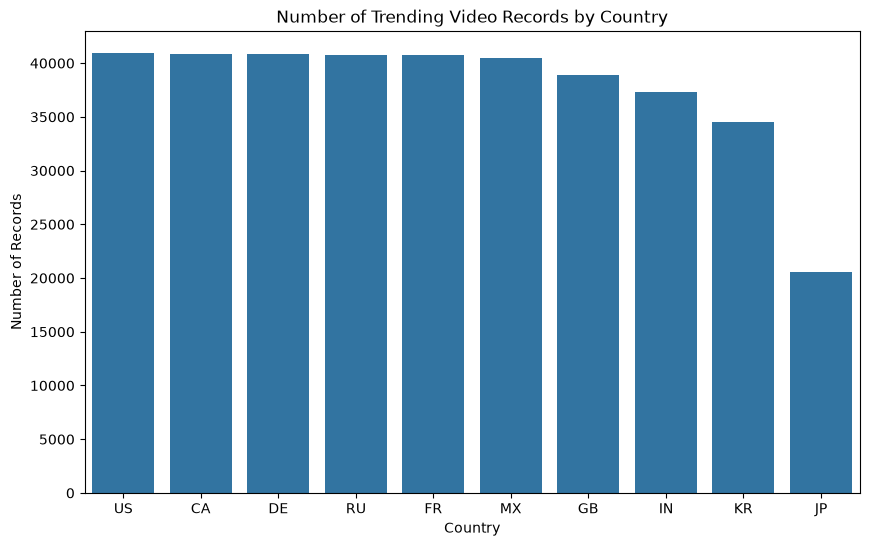

In [20]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="country",
    order=df["country"].value_counts().index
)

plt.title("Number of Trending Video Records by Country")
plt.xlabel("Country")
plt.ylabel("Number of Records")

plt.show()

In [21]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 375942 entries, 0 to 375941
Data columns (total 17 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   video_id                375942 non-null  str  
 1   trending_date           375942 non-null  str  
 2   title                   375942 non-null  str  
 3   channel_title           375942 non-null  str  
 4   category_id             375942 non-null  int64
 5   publish_time            375942 non-null  str  
 6   tags                    375942 non-null  str  
 7   views                   375942 non-null  int64
 8   likes                   375942 non-null  int64
 9   dislikes                375942 non-null  int64
 10  comment_count           375942 non-null  int64
 11  thumbnail_link          375942 non-null  str  
 12  comments_disabled       375942 non-null  bool 
 13  ratings_disabled        375942 non-null  bool 
 14  video_error_or_removed  375942 non-null  bool 
 15  description

## Understanding the JSON Category Mapping Files

The CSV files contain numerical `category_id` values. These IDs do not directly provide meaningful information about the video category.

The JSON files contain mappings between category IDs and category names. A sample JSON file is examined to understand its structure before extracting category information.

In [22]:
with open(json_files[0], "r", encoding="utf-8") as file:
    sample_json = json.load(file)

print("Top-level keys:", sample_json.keys())
print("\nFirst category entry:")
print(sample_json["items"][0])

Top-level keys: dict_keys(['kind', 'etag', 'items'])

First category entry:
{'kind': 'youtube#videoCategory', 'etag': '"ld9biNPKjAjgjV7EZ4EKeEGrhao/Xy1mB4_yLrHy_BmKmPBggty2mZQ"', 'id': '1', 'snippet': {'channelId': 'UCBR8-60-B28hp2BmDPdntcQ', 'title': 'Film & Animation', 'assignable': True}}


## Creating a Function to Extract Category Mappings

A reusable function is created to extract category IDs and their corresponding category names from each JSON file.

The function returns a dictionary where the category ID is the key and the category name is the value.

In [23]:
def load_category_mapping(json_file):
    
    with open(json_file, "r", encoding="utf-8") as file:
        data = json.load(file)
    
    category_mapping = {}
    
    for item in data["items"]:
        category_id = int(item["id"])
        category_name = item["snippet"]["title"]
        
        category_mapping[category_id] = category_name
    
    return category_mapping

In [24]:
test_mapping = load_category_mapping(json_files[0])

print("Number of Categories:", len(test_mapping))
print("\nCategory Mapping:")
print(test_mapping)

Number of Categories: 31

Category Mapping:
{1: 'Film & Animation', 2: 'Autos & Vehicles', 10: 'Music', 15: 'Pets & Animals', 17: 'Sports', 18: 'Short Movies', 19: 'Travel & Events', 20: 'Gaming', 21: 'Videoblogging', 22: 'People & Blogs', 23: 'Comedy', 24: 'Entertainment', 25: 'News & Politics', 26: 'Howto & Style', 27: 'Education', 28: 'Science & Technology', 30: 'Movies', 31: 'Anime/Animation', 32: 'Action/Adventure', 33: 'Classics', 34: 'Comedy', 35: 'Documentary', 36: 'Drama', 37: 'Family', 38: 'Foreign', 39: 'Horror', 40: 'Sci-Fi/Fantasy', 41: 'Thriller', 42: 'Shorts', 43: 'Shows', 44: 'Trailers'}


In [25]:
country_category_mappings = {}

for json_file in json_files:
    
    country_code = os.path.basename(json_file)[:2]
    
    country_category_mappings[country_code] = load_category_mapping(json_file)

print("Country mappings created for:")
print(list(country_category_mappings.keys()))

Country mappings created for:
['CA', 'DE', 'FR', 'GB', 'IN', 'JP', 'KR', 'MX', 'RU', 'US']


In [26]:
combined_category_mapping = {}

for country, mapping in country_category_mappings.items():
    
    for category_id, category_name in mapping.items():
        
        combined_category_mapping[(country, category_id)] = category_name

print("Total category mappings:", len(combined_category_mapping))

Total category mappings: 311


## Mapping Category IDs to Category Names

A new column named `category_name` is created by mapping each video's country and category ID to the corresponding category name.

This provides meaningful categorical information and avoids treating category IDs as numerical quantities.

In [27]:
df["category_name"] = [
    combined_category_mapping.get(
        (country, category_id),
        "Unknown"
    )
    for country, category_id in zip(
        df["country"],
        df["category_id"]
    )
]

print("Category names added successfully.")

Category names added successfully.


In [28]:
df[
    ["country", "category_id", "category_name"]
].head(15)

,country,category_id,category_name
0,CA,10,Music
1,CA,23,Comedy
2,CA,23,Comedy
3,CA,24,Entertainment
4,CA,10,Music
5,CA,25,News & Politics
6,CA,23,Comedy
7,CA,22,People & Blogs
8,CA,24,Entertainment
9,CA,22,People & Blogs


# Checking for Unmapped Categories

In [29]:
unknown_count = (df["category_name"] == "Unknown").sum()

print("Number of Unknown Categories:", unknown_count)

if unknown_count == 0:
    print("All category IDs were mapped successfully.")
else:
    print("\nUnmapped category combinations:")
    
    display(
        df.loc[
            df["category_name"] == "Unknown",
            ["country", "category_id"]
        ].drop_duplicates()
    )

Number of Unknown Categories: 2738

Unmapped category combinations:


,country,category_id
43,CA,29
41167,DE,29
82273,FR,29
130064,GB,29
161501,IN,29
198880,JP,29
219354,KR,29
253859,MX,29
294311,RU,29


In [30]:
category_counts = df["category_name"].value_counts()

print(category_counts)

category_name
Entertainment            109006
People & Blogs            54052
Music                     42514
News & Politics           37288
Comedy                    26970
Sports                    23684
Film & Animation          20932
Howto & Style             18856
Gaming                    11498
Science & Technology       8171
Education                  7788
Pets & Animals             4863
Autos & Vehicles           4734
Unknown                    2738
Travel & Events            1776
Shows                       974
Nonprofits & Activism        57
Movies                       36
Trailers                      5
Name: count, dtype: int64


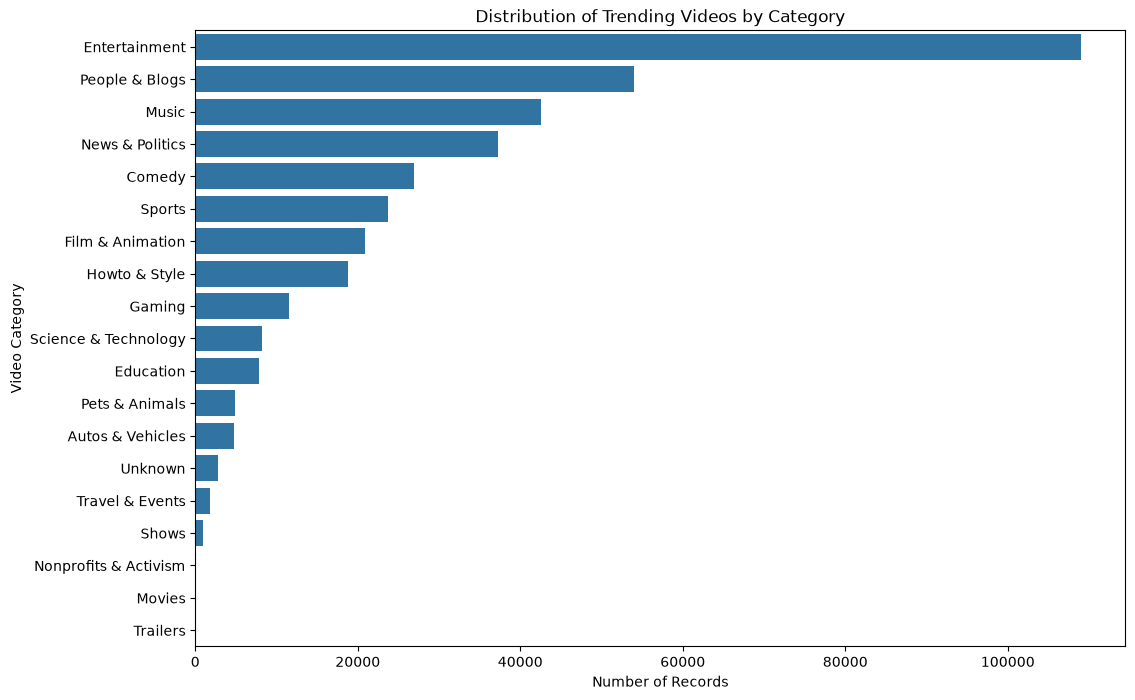

In [31]:
plt.figure(figsize=(12, 8))

sns.countplot(
    data=df,
    y="category_name",
    order=df["category_name"].value_counts().index
)

plt.title("Distribution of Trending Videos by Category")
plt.xlabel("Number of Records")
plt.ylabel("Video Category")

plt.show()

In [32]:
print("Dataset Shape:", df.shape)

print("\nNumber of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Dataset Shape: (375942, 18)

Number of Rows: 375942
Number of Columns: 18


In [33]:
print("Dataset Columns and Data Types:\n")

print(df.dtypes)

Dataset Columns and Data Types:

video_id                    str
trending_date               str
title                       str
channel_title               str
category_id               int64
publish_time                str
tags                        str
views                     int64
likes                     int64
dislikes                  int64
comment_count             int64
thumbnail_link              str
comments_disabled          bool
ratings_disabled           bool
video_error_or_removed     bool
description                 str
country                     str
category_name               str
dtype: object


In [34]:
missing_values = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": (df.isnull().sum() / len(df)) * 100
})

missing_values = missing_values[
    missing_values["Missing Values"] > 0
].sort_values(
    by="Missing Values",
    ascending=False
)

missing_values

,Missing Values,Percentage
description,19478,5.181118


In [35]:
duplicate_count = df.duplicated().sum()

print("Number of Duplicate Rows:", duplicate_count)
print("Duplicate Percentage:", round((duplicate_count / len(df)) * 100, 2), "%")

Number of Duplicate Rows: 12570
Duplicate Percentage: 3.34 %


In [36]:
if duplicate_count > 0:
    
    duplicate_rows = df[df.duplicated(keep=False)]
    
    display(duplicate_rows.head())
    
else:
    print("No completely duplicated rows found.")

,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description,country,category_name
156074,RUCXD3_wW2w,18.14.05,New Hulu Show - SNL,Saturday Night Live,24,2018-05-13T04:59:28.000Z,"SNL|""Saturday Night Live""|""SNL Season 43""|""SNL...",723495,6362,1589,420,https://i.ytimg.com/vi/RUCXD3_wW2w/default.jpg,False,False,False,From the executive producer of Sex and the Cit...,GB,Entertainment
156075,p8npDG2ulKQ,18.14.05,BTS (방탄소년단) LOVE YOURSELF 轉 Tear 'Singularity'...,ibighit,10,2018-05-06T15:00:02.000Z,"BIGHIT|""빅히트""|""방탄소년단""|""BTS""|""BANGTAN""|""방탄""",26912663,2636004,27675,366899,https://i.ytimg.com/vi/p8npDG2ulKQ/default.jpg,False,False,False,BTS (방탄소년단) LOVE YOURSELF 轉 Tear 'Singularity'...,GB,Music
156076,aixso4N2vhI,18.14.05,President Trump Gives Remarks on the Joint Com...,The White House,25,2018-05-08T18:45:37.000Z,[none],89715,2806,488,1657,https://i.ytimg.com/vi/aixso4N2vhI/default.jpg,False,False,False,The White House,GB,News & Politics
156077,bu0m_UdtoaU,18.14.05,Serious Questions: Avengers Infinity War,Screen Junkies,1,2018-05-06T17:00:03.000Z,"screenjunkies|""screen junkies""|""serious questi...",443621,12892,3829,2275,https://i.ytimg.com/vi/bu0m_UdtoaU/default.jpg,False,False,False,After watching Avengers: Infinity War we have ...,GB,Film & Animation
156078,i-G1hy73Mb8,18.14.05,Eurovision Song Contest 2018 - Opening Ceremon...,Eurovision Song Contest,24,2018-05-06T19:46:34.000Z,"Eurovision Song Contest|""2018""|""Lisbon""|""Openi...",698827,11721,461,1175,https://i.ytimg.com/vi/i-G1hy73Mb8/default.jpg,False,False,False,"At 18:00 CEST today, the Blue Carpet ceremony ...",GB,Entertainment


In [37]:
rows_before = len(df)

df = df.drop_duplicates().copy()

rows_after = len(df)

print("Rows before removing duplicates:", rows_before)
print("Rows after removing duplicates:", rows_after)
print("Duplicates removed:", rows_before - rows_after)

Rows before removing duplicates: 375942
Rows after removing duplicates: 363372
Duplicates removed: 12570


In [38]:
numerical_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

df[numerical_columns].describe().T

Numerical Columns:
['category_id', 'views', 'likes', 'dislikes', 'comment_count']


,count,mean,std,min,25%,50%,75%,max
category_id,363372.0,2.021964e+01,7.142501e+00,1.0,17.0,23.0,24.00,44.0
views,363372.0,1.343185e+06,7.192440e+06,117.0,46297.5,176281.0,650022.75,424538912.0
likes,363372.0,3.841334e+04,1.661261e+05,0.0,673.0,3516.0,17859.50,5613827.0
dislikes,363372.0,2.156429e+03,2.284087e+04,0.0,41.0,179.0,753.00,1944971.0
comment_count,363372.0,4.303169e+03,2.542733e+04,0.0,109.0,518.0,2047.00,1626501.0


## Defining the Target Variable

The target variable for this project is `views`.

The objective of the Machine Learning model is to predict the number of views received by a trending YouTube video.

Since views are continuous numerical values, this project is treated as a regression problem.

In [39]:
target_column = "views"

print("Target Variable:", target_column)
print("Target Data Type:", df[target_column].dtype)

Target Variable: views
Target Data Type: int64


## Log Transformation Analysis of Views

YouTube view counts are expected to have a highly right-skewed distribution because a small number of viral videos receive extremely high views.

A logarithmic transformation is visualized to reduce skewness and better understand the distribution of the target variable.

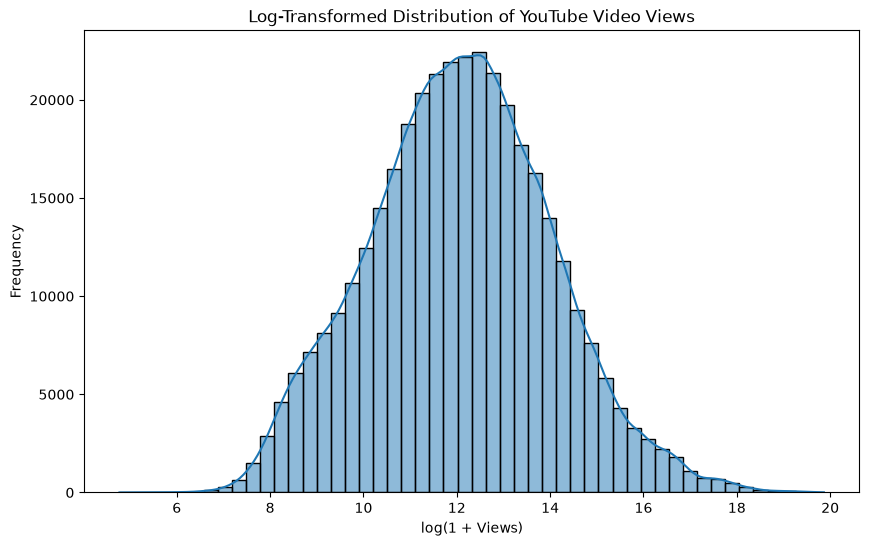

In [40]:
log_views = np.log1p(df["views"])

plt.figure(figsize=(10, 6))

sns.histplot(
    log_views,
    bins=50,
    kde=True
)

plt.title("Log-Transformed Distribution of YouTube Video Views")
plt.xlabel("log(1 + Views)")
plt.ylabel("Frequency")

plt.show()

## Outlier Analysis of Engagement Metrics

Boxplots are used to examine the presence of extreme values in major numerical engagement features.

Extreme values are not automatically removed because viral YouTube videos naturally receive unusually high views and engagement.

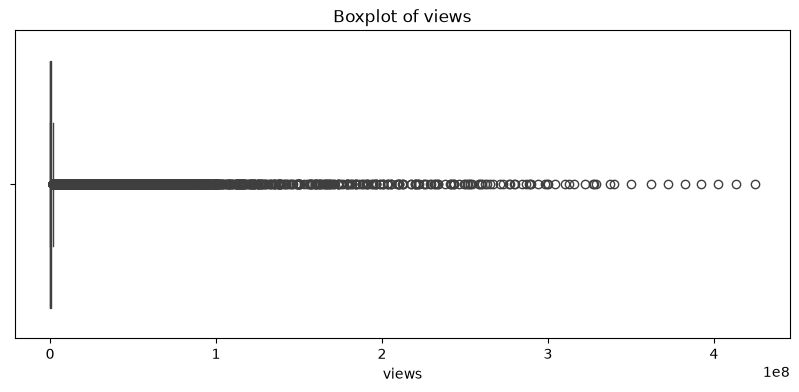

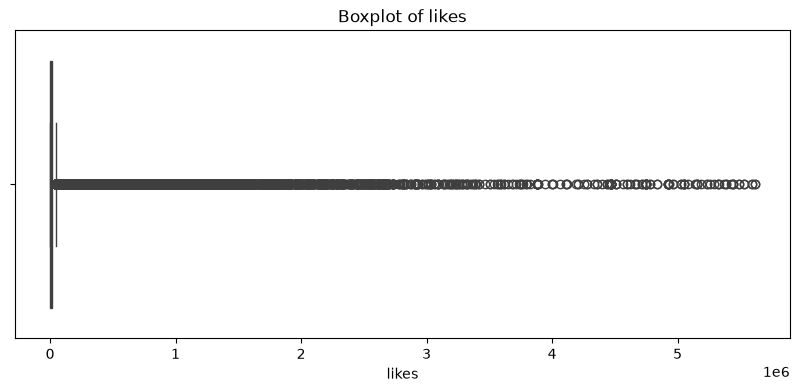

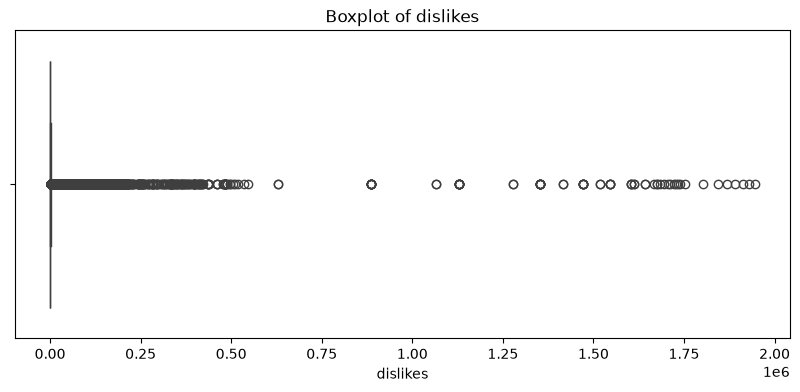

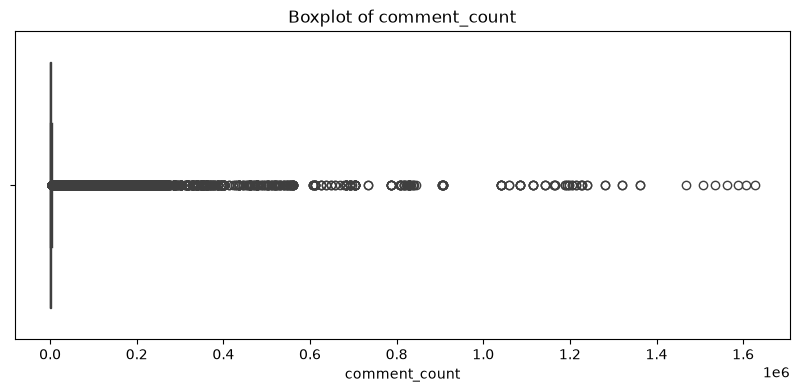

In [41]:
engagement_columns = [
    "views",
    "likes",
    "dislikes",
    "comment_count"
]

for column in engagement_columns:
    
    plt.figure(figsize=(10, 4))
    
    sns.boxplot(x=df[column])
    
    plt.title(f"Boxplot of {column}")
    
    plt.show()

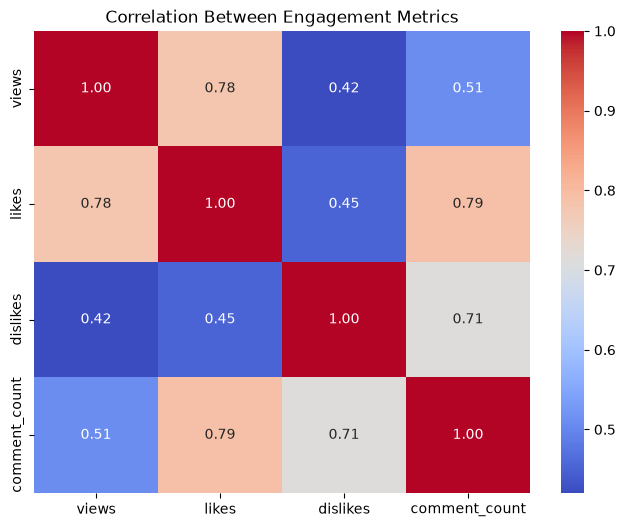

In [42]:
correlation_columns = [
    "views",
    "likes",
    "dislikes",
    "comment_count"
]

correlation_matrix = df[correlation_columns].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Between Engagement Metrics")

plt.show()

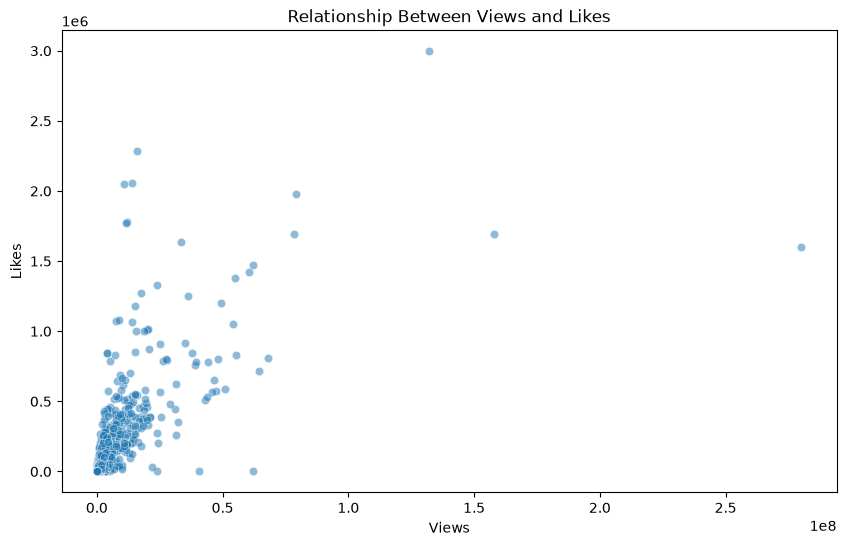

In [43]:
plot_sample = df.sample(
    n=min(5000, len(df)),
    random_state=42
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=plot_sample,
    x="views",
    y="likes",
    alpha=0.5
)

plt.title("Relationship Between Views and Likes")
plt.xlabel("Views")
plt.ylabel("Likes")

plt.show()

In [44]:
category_avg_views = (
    df.groupby("category_name")["views"]
    .mean()
    .sort_values(ascending=False)
)

print(category_avg_views)

category_name
Music                    6.094538e+06
Nonprofits & Activism    2.963884e+06
Movies                   1.774643e+06
Film & Animation         1.327032e+06
Science & Technology     1.115871e+06
Entertainment            9.635065e+05
Comedy                   8.203270e+05
Sports                   8.078187e+05
Gaming                   6.818134e+05
Howto & Style            5.204091e+05
Shows                    4.430091e+05
People & Blogs           4.407818e+05
Pets & Animals           4.350063e+05
Travel & Events          4.183125e+05
Unknown                  3.868057e+05
Education                3.538062e+05
Autos & Vehicles         3.529617e+05
News & Politics          2.769876e+05
Trailers                 1.100860e+04
Name: views, dtype: float64


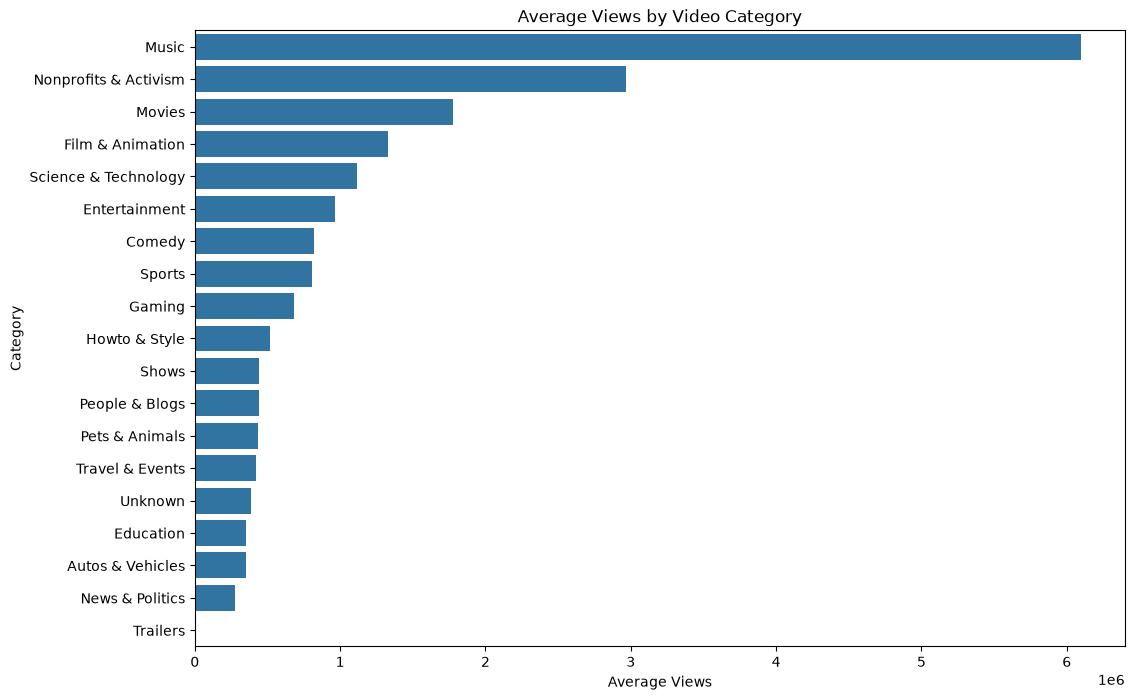

In [45]:
plt.figure(figsize=(12, 8))

sns.barplot(
    x=category_avg_views.values,
    y=category_avg_views.index
)

plt.title("Average Views by Video Category")
plt.xlabel("Average Views")
plt.ylabel("Category")

plt.show()

In [46]:
country_avg_views = (
    df.groupby("country")["views"]
    .mean()
    .sort_values(ascending=False)
)

print(country_avg_views)

country
GB    5.911293e+06
US    2.360678e+06
CA    1.147036e+06
IN    9.963425e+05
DE    6.034553e+05
KR    4.233832e+05
FR    4.199219e+05
MX    3.401750e+05
JP    2.537013e+05
RU    2.388132e+05
Name: views, dtype: float64


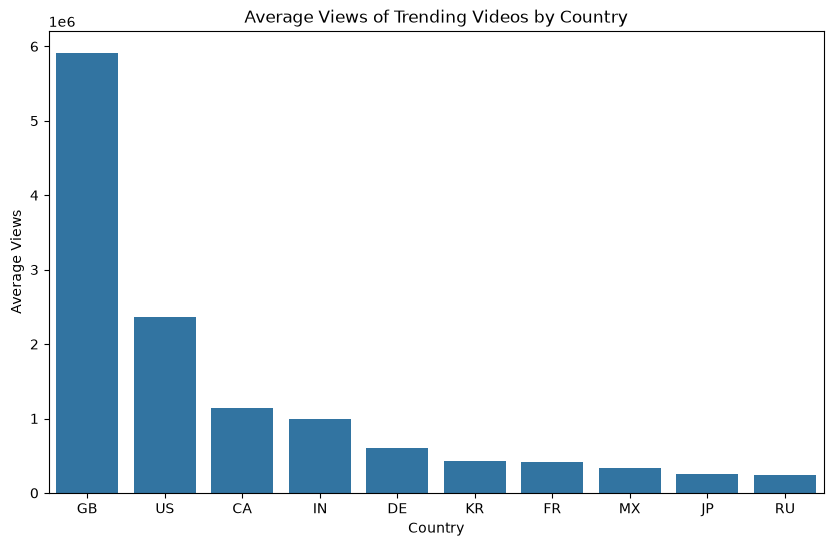

In [47]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=country_avg_views.index,
    y=country_avg_views.values
)

plt.title("Average Views of Trending Videos by Country")
plt.xlabel("Country")
plt.ylabel("Average Views")

plt.show()

## EDA Summary

The exploratory analysis revealed that the YouTube trending dataset contains videos from multiple countries and categories with significant variation in engagement metrics.

The target variable, `views`, shows a highly right-skewed distribution due to the presence of viral videos with extremely high view counts. These extreme values are considered meaningful observations rather than data errors and are therefore not blindly removed.

Engagement metrics such as likes, dislikes, and comment count show relationships with video views. Category and country information may also contribute useful predictive information.

Based on these observations, the next stage will focus on selecting relevant features, handling missing values where necessary, engineering useful date-time features, encoding categorical variables, and preparing the dataset for Machine Learning model development.

# Feature Engineering

Feature engineering is performed to transform raw dataset columns into meaningful features that can be used by Machine Learning models.

A copy of the cleaned dataset is created to preserve the original processed dataset before applying feature transformations.

In [48]:
ml_df = df.copy()

print("Feature Engineering Dataset Shape:", ml_df.shape)

Feature Engineering Dataset Shape: (363372, 18)


## Converting Date Columns to Datetime Format

The `publish_time` and `trending_date` columns are converted into datetime format.

This allows useful time-based features such as year, month, day, and hour to be extracted for Machine Learning.

In [49]:
print("Before Conversion:")
print(ml_df[["publish_time", "trending_date"]].dtypes)

ml_df["publish_time"] = pd.to_datetime(
    ml_df["publish_time"],
    errors="coerce"
)

ml_df["trending_date"] = pd.to_datetime(
    ml_df["trending_date"],
    errors="coerce"
)

print("\nAfter Conversion:")
print(ml_df[["publish_time", "trending_date"]].dtypes)

Before Conversion:
publish_time     str
trending_date    str
dtype: object

After Conversion:
publish_time     datetime64[us, UTC]
trending_date         datetime64[us]
dtype: object


In [50]:
print("Missing Publish Dates:", ml_df["publish_time"].isnull().sum())
print("Missing Trending Dates:", ml_df["trending_date"].isnull().sum())

Missing Publish Dates: 0
Missing Trending Dates: 226476


In [51]:
ml_df["publish_year"] = ml_df["publish_time"].dt.year
ml_df["publish_month"] = ml_df["publish_time"].dt.month
ml_df["publish_day"] = ml_df["publish_time"].dt.day
ml_df["publish_dayofweek"] = ml_df["publish_time"].dt.dayofweek
ml_df["publish_hour"] = ml_df["publish_time"].dt.hour

ml_df[
    [
        "publish_time",
        "publish_year",
        "publish_month",
        "publish_day",
        "publish_dayofweek",
        "publish_hour"
    ]
].head()

,publish_time,publish_year,publish_month,publish_day,publish_dayofweek,publish_hour
0,2017-11-10 17:00:03+00:00,2017,11,10,4,17
1,2017-11-13 17:00:00+00:00,2017,11,13,0,17
2,2017-11-12 19:05:24+00:00,2017,11,12,6,19
3,2017-11-12 18:01:41+00:00,2017,11,12,6,18
4,2017-11-09 11:04:14+00:00,2017,11,9,3,11


In [52]:
ml_df["trending_year"] = ml_df["trending_date"].dt.year
ml_df["trending_month"] = ml_df["trending_date"].dt.month
ml_df["trending_day"] = ml_df["trending_date"].dt.day
ml_df["trending_dayofweek"] = ml_df["trending_date"].dt.dayofweek

ml_df[
    [
        "trending_date",
        "trending_year",
        "trending_month",
        "trending_day",
        "trending_dayofweek"
    ]
].head()

,trending_date,trending_year,trending_month,trending_day,trending_dayofweek
0,NaT,NaN,NaN,NaN,NaN
1,NaT,NaN,NaN,NaN,NaN
2,NaT,NaN,NaN,NaN,NaN
3,NaT,NaN,NaN,NaN,NaN
4,NaT,NaN,NaN,NaN,NaN


## Creating the Days to Trending Feature

A new feature named `days_to_trending` is created by calculating the difference between the trending date and publication date.

This feature represents how quickly a video appeared in the trending list after being published.

In [62]:
test_df = pd.read_csv(
    csv_files[0],
    encoding="latin1"
)

print(test_df["trending_date"].head(10))
print(test_df["trending_date"].dtype)

0    17.14.11
1    17.14.11
2    17.14.11
3    17.14.11
4    17.14.11
5    17.14.11
6    17.14.11
7    17.14.11
8    17.14.11
9    17.14.11
Name: trending_date, dtype: str
str


In [63]:
dataframes = []

for file in csv_files:
    try:
        temp_df = pd.read_csv(file, encoding="utf-8")
    except UnicodeDecodeError:
        temp_df = pd.read_csv(file, encoding="latin1")

    dataframes.append(temp_df)

raw_df = pd.concat(dataframes, ignore_index=True)

print("Combined Shape:", raw_df.shape)
print(raw_df["trending_date"].head(10))

Combined Shape: (375942, 16)
0    17.14.11
1    17.14.11
2    17.14.11
3    17.14.11
4    17.14.11
5    17.14.11
6    17.14.11
7    17.14.11
8    17.14.11
9    17.14.11
Name: trending_date, dtype: str


In [64]:
raw_df["trending_date"] = pd.to_datetime(
    raw_df["trending_date"].astype(str),
    format="%y.%d.%m",
    errors="coerce"
)

In [65]:
print(raw_df["trending_date"].head(10))
print("Missing trending dates:", raw_df["trending_date"].isna().sum())

0   2017-11-14
1   2017-11-14
2   2017-11-14
3   2017-11-14
4   2017-11-14
5   2017-11-14
6   2017-11-14
7   2017-11-14
8   2017-11-14
9   2017-11-14
Name: trending_date, dtype: datetime64[us]
Missing trending dates: 0


In [66]:
raw_df["publish_time"] = pd.to_datetime(
    raw_df["publish_time"],
    errors="coerce",
    utc=True
).dt.tz_localize(None)

In [67]:
raw_df["days_to_trending"] = (
    raw_df["trending_date"].dt.normalize()
    - raw_df["publish_time"].dt.normalize()
).dt.days

In [68]:
display(
    raw_df[
        ["publish_time", "trending_date", "days_to_trending"]
    ].head(10)
)

print("Missing:", raw_df["days_to_trending"].isna().sum())
print("Negative:", (raw_df["days_to_trending"] < 0).sum())
print(raw_df["days_to_trending"].describe())

,publish_time,trending_date,days_to_trending
0,2017-11-10 17:00:03,2017-11-14,4
1,2017-11-13 17:00:00,2017-11-14,1
2,2017-11-12 19:05:24,2017-11-14,2
3,2017-11-12 18:01:41,2017-11-14,2
4,2017-11-09 11:04:14,2017-11-14,5
5,2017-11-13 07:37:51,2017-11-14,1
6,2017-11-12 23:52:13,2017-11-14,2
7,2017-11-13 17:13:01,2017-11-14,1
8,2017-11-12 20:19:24,2017-11-14,2
9,2017-11-10 14:10:46,2017-11-14,4


Missing: 0
Negative: 0
count    375942.000000
mean          7.498268
std          97.363787
min           0.000000
25%           1.000000
50%           1.000000
75%           3.000000
max        4215.000000
Name: days_to_trending, dtype: float64


In [70]:
# Check unusually high days_to_trending values

ml_df = raw_df.copy()

extreme_days = ml_df[
    ml_df["days_to_trending"] > 30
][[
    "video_id",
    "publish_time",
    "trending_date",
    "days_to_trending",
    "title"
]].sort_values(
    by="days_to_trending",
    ascending=False
)

print("Videos taking more than 30 days to trend:", len(extreme_days))

display(extreme_days.head(20))

Videos taking more than 30 days to trend: 3460


,video_id,publish_time,trending_date,days_to_trending,title
351287,MJO3FmmFuh4,2006-07-23 08:24:11,2018-02-05,4215,Budweiser - Original Whazzup? ad
138816,tP_Dk81f9fg,2007-03-05 16:23:55,2018-02-05,3990,Jeffrey Lewis The Legend of The Fall
138605,tP_Dk81f9fg,2007-03-05 16:23:55,2018-02-04,3989,Jeffrey Lewis The Legend of The Fall
138392,tP_Dk81f9fg,2007-03-05 16:23:55,2018-02-03,3988,Jeffrey Lewis The Legend of The Fall
138175,tP_Dk81f9fg,2007-03-05 16:23:55,2018-02-02,3987,Jeffrey Lewis The Legend of The Fall
137959,tP_Dk81f9fg,2007-03-05 16:23:55,2018-02-01,3986,Jeffrey Lewis The Legend of The Fall
137735,tP_Dk81f9fg,2007-03-05 16:23:55,2018-01-31,3985,Jeffrey Lewis The Legend of The Fall
137525,tP_Dk81f9fg,2007-03-05 16:23:55,2018-01-30,3984,Jeffrey Lewis The Legend of The Fall
137308,tP_Dk81f9fg,2007-03-05 16:23:55,2018-01-29,3983,Jeffrey Lewis The Legend of The Fall
137099,tP_Dk81f9fg,2007-03-05 16:23:55,2018-01-28,3982,Jeffrey Lewis The Legend of The Fall


## Engineering Title-Based Features

The raw video title is converted into numerical features such as title length and word count.

These features capture basic characteristics of video titles without requiring complex Natural Language Processing techniques.

In [71]:
ml_df["title_length"] = ml_df["title"].fillna("").str.len()

ml_df["title_word_count"] = (
    ml_df["title"]
    .fillna("")
    .str.split()
    .str.len()
)

ml_df[
    [
        "title",
        "title_length",
        "title_word_count"
    ]
].head()

,title,title_length,title_word_count
0,Eminem - Walk On Water (Audio) ft. Beyoncé,42,8
1,PLUSH - Bad Unboxing Fan Mail,29,6
2,"Racist Superman | Rudy Mancuso, King Bach & Le...",53,10
3,I Dare You: GOING BALD!?,24,5
4,Ed Sheeran - Perfect (Official Music Video),43,7


## Engineering Description-Based Features

The description column contains unstructured text. Instead of directly using raw text, numerical features such as description length and word count are extracted.

These features provide information about the amount of descriptive content associated with each video.

In [72]:
ml_df["description_length"] = (
    ml_df["description"]
    .fillna("")
    .str.len()
)

ml_df["description_word_count"] = (
    ml_df["description"]
    .fillna("")
    .str.split()
    .str.len()
)

ml_df[
    [
        "description_length",
        "description_word_count"
    ]
].head()

,description_length,description_word_count
0,594,34
1,704,61
2,1177,74
3,636,53
4,1250,118


## Engineering Tag-Based Features

The number of tags associated with each video is calculated.

Tags are separated using the pipe (`|`) character. The number of tags may provide useful metadata about the video.

In [73]:
ml_df["tag_count"] = (
    ml_df["tags"]
    .fillna("")
    .apply(
        lambda x: 0 if x == "[none]" else len(x.split("|"))
    )
)

ml_df[
    [
        "tags",
        "tag_count"
    ]
].head()

,tags,tag_count
0,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",6
1,"plush|""bad unboxing""|""unboxing""|""fan mail""|""id...",11
2,"racist superman|""rudy""|""mancuso""|""king""|""bach""...",23
3,"ryan|""higa""|""higatv""|""nigahiga""|""i dare you""|""...",14
4,"edsheeran|""ed sheeran""|""acoustic""|""live""|""cove...",10


## Converting Boolean Features

Boolean columns are converted into binary numerical values where True is represented as 1 and False is represented as 0.

This conversion makes the features compatible with Machine Learning algorithms.

In [74]:
boolean_columns = [
    "comments_disabled",
    "ratings_disabled",
    "video_error_or_removed"
]

for column in boolean_columns:
    ml_df[column] = ml_df[column].astype(int)

ml_df[boolean_columns].head()

,comments_disabled,ratings_disabled,video_error_or_removed
0,0,0,0
1,0,0,0
2,0,0,0
3,0,0,0
4,0,0,0


In [75]:
missing_after_engineering = ml_df.isnull().sum()

missing_after_engineering = missing_after_engineering[
    missing_after_engineering > 0
].sort_values(ascending=False)

missing_after_engineering

description    19478
dtype: int64

In [77]:
# Features from publish_time

ml_df["publish_year"] = ml_df["publish_time"].dt.year
ml_df["publish_month"] = ml_df["publish_time"].dt.month
ml_df["publish_day"] = ml_df["publish_time"].dt.day
ml_df["publish_dayofweek"] = ml_df["publish_time"].dt.dayofweek
ml_df["publish_hour"] = ml_df["publish_time"].dt.hour


# Features from trending_date

ml_df["trending_year"] = ml_df["trending_date"].dt.year
ml_df["trending_month"] = ml_df["trending_date"].dt.month
ml_df["trending_day"] = ml_df["trending_date"].dt.day
ml_df["trending_dayofweek"] = ml_df["trending_date"].dt.dayofweek


print("Date-based features created successfully.")

Date-based features created successfully.


In [78]:
engineered_numeric_columns = [
    "publish_year",
    "publish_month",
    "publish_day",
    "publish_dayofweek",
    "publish_hour",
    "trending_year",
    "trending_month",
    "trending_day",
    "trending_dayofweek",
    "days_to_trending",
    "title_length",
    "title_word_count",
    "description_length",
    "description_word_count",
    "tag_count"
]

for column in engineered_numeric_columns:
    
    if ml_df[column].isnull().sum() > 0:
        
        ml_df[column] = ml_df[column].fillna(
            ml_df[column].median()
        )

print("Missing values handled successfully.")

Missing values handled successfully.


In [79]:
new_features = [
    "publish_year",
    "publish_month",
    "publish_day",
    "publish_dayofweek",
    "publish_hour",
    "trending_year",
    "trending_month",
    "trending_day",
    "trending_dayofweek",
    "days_to_trending",
    "title_length",
    "title_word_count",
    "description_length",
    "description_word_count",
    "tag_count"
]

ml_df[new_features].head()

,publish_year,publish_month,publish_day,publish_dayofweek,publish_hour,trending_year,trending_month,trending_day,trending_dayofweek,days_to_trending,title_length,title_word_count,description_length,description_word_count,tag_count
0,2017,11,10,4,17,2017,11,14,1,4,42,8,594,34,6
1,2017,11,13,0,17,2017,11,14,1,1,29,6,704,61,11
2,2017,11,12,6,19,2017,11,14,1,2,53,10,1177,74,23
3,2017,11,12,6,18,2017,11,14,1,2,24,5,636,53,14
4,2017,11,9,3,11,2017,11,14,1,5,43,7,1250,118,10


In [80]:
print("Available Columns:\n")

for i, column in enumerate(ml_df.columns, start=1):
    print(f"{i}. {column}")

Available Columns:

1. video_id
2. trending_date
3. title
4. channel_title
5. category_id
6. publish_time
7. tags
8. views
9. likes
10. dislikes
11. comment_count
12. thumbnail_link
13. comments_disabled
14. ratings_disabled
15. video_error_or_removed
16. description
17. days_to_trending
18. title_length
19. title_word_count
20. description_length
21. description_word_count
22. tag_count
23. publish_year
24. publish_month
25. publish_day
26. publish_dayofweek
27. publish_hour
28. trending_year
29. trending_month
30. trending_day
31. trending_dayofweek


## Removing Unnecessary and Potential Leakage Features

Several columns are excluded from the Machine Learning dataset.

Unique identifiers and raw text fields are removed because they cannot be directly used by traditional Machine Learning models without additional NLP processing.

The original date columns are removed because useful numerical features have already been extracted from them.

Engagement metrics such as likes, dislikes, and comment count are excluded to avoid potential data leakage, since these values are closely associated with the number of views and may not be available at the intended prediction stage.

In [81]:
columns_to_drop = [
    "video_id",
    "title",
    "channel_title",
    "tags",
    "description",
    "thumbnail_link",
    "publish_time",
    "trending_date",
    "likes",
    "dislikes",
    "comment_count"
]

print("Columns selected for removal:")

for column in columns_to_drop:
    print("-", column)

Columns selected for removal:
- video_id
- title
- channel_title
- tags
- description
- thumbnail_link
- publish_time
- trending_date
- likes
- dislikes
- comment_count


In [82]:
X = ml_df.drop(
    columns=columns_to_drop + ["views"]
)

y = ml_df["views"]

print("Feature Dataset Shape:", X.shape)
print("Target Dataset Shape:", y.shape)

Feature Dataset Shape: (375942, 19)
Target Dataset Shape: (375942,)


In [83]:
print("Final Features Used for Machine Learning:\n")

for i, column in enumerate(X.columns, start=1):
    print(f"{i}. {column}")

Final Features Used for Machine Learning:

1. category_id
2. comments_disabled
3. ratings_disabled
4. video_error_or_removed
5. days_to_trending
6. title_length
7. title_word_count
8. description_length
9. description_word_count
10. tag_count
11. publish_year
12. publish_month
13. publish_day
14. publish_dayofweek
15. publish_hour
16. trending_year
17. trending_month
18. trending_day
19. trending_dayofweek


In [84]:
print("Missing Values in Features:")
print(X.isnull().sum()[X.isnull().sum() > 0])

print("\nMissing Values in Target:")
print(y.isnull().sum())

Missing Values in Features:
Series([], dtype: int64)

Missing Values in Target:
0


## Identifying Numerical and Categorical Features

The selected features are separated into numerical and categorical groups.

Numerical features may require scaling, while categorical features need encoding before being used by Machine Learning algorithms.

In [85]:
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['category_id', 'comments_disabled', 'ratings_disabled', 'video_error_or_removed', 'days_to_trending', 'title_length', 'title_word_count', 'description_length', 'description_word_count', 'tag_count']

Categorical Features:
[]


In [86]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 375942 entries, 0 to 375941
Data columns (total 19 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   category_id             375942 non-null  int64
 1   comments_disabled       375942 non-null  int64
 2   ratings_disabled        375942 non-null  int64
 3   video_error_or_removed  375942 non-null  int64
 4   days_to_trending        375942 non-null  int64
 5   title_length            375942 non-null  int64
 6   title_word_count        375942 non-null  int64
 7   description_length      375942 non-null  int64
 8   description_word_count  375942 non-null  int64
 9   tag_count               375942 non-null  int64
 10  publish_year            375942 non-null  int32
 11  publish_month           375942 non-null  int32
 12  publish_day             375942 non-null  int32
 13  publish_dayofweek       375942 non-null  int32
 14  publish_hour            375942 non-null  int32
 15  trending_ye

In [87]:
print(y.describe())

count    3.759420e+05
mean     1.326568e+06
std      7.098568e+06
min      1.170000e+02
25%      4.697800e+04
50%      1.773705e+05
75%      6.476792e+05
max      4.245389e+08
Name: views, dtype: float64


In [88]:
y_log = np.log1p(y)

print("Original Target:")
print(y.head())

print("\nLog Transformed Target:")
print(y_log.head())

Original Target:
0    17158579
1     1014651
2     3191434
3     2095828
4    33523622
Name: views, dtype: int64

Log Transformed Target:
0    16.658009
1    13.830056
2    14.975981
3    14.555460
4    17.327761
Name: views, dtype: float64


In [89]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_log,
    test_size=0.20,
    random_state=42
)

print("Training Feature Shape:", X_train.shape)
print("Testing Feature Shape:", X_test.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Feature Shape: (300753, 19)
Testing Feature Shape: (75189, 19)

Training Target Shape: (300753,)
Testing Target Shape: (75189,)


In [90]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [91]:
numerical_transformer = Pipeline(
    steps=[
        ("scaler", StandardScaler())
    ]
)

In [92]:
categorical_transformer = Pipeline(
    steps=[
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

In [93]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numerical_transformer,
            numerical_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

In [94]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Processed Training Shape:", X_train_processed.shape)
print("Processed Testing Shape:", X_test_processed.shape)

Processed Training Shape: (300753, 10)
Processed Testing Shape: (75189, 10)


In [95]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import HistGradientBoostingRegressor

In [96]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [97]:
def evaluate_model(model, X_test, y_test):
    
    # Predictions on log scale
    predictions_log = model.predict(X_test)
    
    # Convert predictions back to original views scale
    predictions = np.expm1(predictions_log)
    
    # Convert actual values back to original views scale
    actual_values = np.expm1(y_test)
    
    # Prevent negative predictions
    predictions = np.maximum(predictions, 0)
    
    # Calculate metrics
    mae = mean_absolute_error(
        actual_values,
        predictions
    )
    
    rmse = np.sqrt(
        mean_squared_error(
            actual_values,
            predictions
        )
    )
    
    r2 = r2_score(
        actual_values,
        predictions
    )
    
    return mae, rmse, r2

In [98]:
linear_model = LinearRegression()

linear_model.fit(
    X_train_processed,
    y_train
)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [99]:
linear_mae, linear_rmse, linear_r2 = evaluate_model(
    linear_model,
    X_test_processed,
    y_test
)

print("Linear Regression Performance")
print("-" * 35)
print(f"MAE  : {linear_mae:,.2f}")
print(f"RMSE : {linear_rmse:,.2f}")
print(f"R²   : {linear_r2:.4f}")

Linear Regression Performance
-----------------------------------
MAE  : 1,235,419.86
RMSE : 7,120,894.62
R²   : -0.0198


In [100]:
model_results = []

model_results.append({
    "Model": "Linear Regression",
    "MAE": linear_mae,
    "RMSE": linear_rmse,
    "R2 Score": linear_r2
})

print("Linear Regression results stored successfully.")

Linear Regression results stored successfully.


In [101]:
linear_predictions_log = linear_model.predict(
    X_test_processed
)

linear_predictions = np.expm1(
    linear_predictions_log
)

linear_predictions = np.maximum(
    linear_predictions,
    0
)

actual_views = np.expm1(y_test)

comparison_df = pd.DataFrame({
    "Actual Views": actual_views.values,
    "Predicted Views": linear_predictions
})

comparison_df.head(10)

,Actual Views,Predicted Views
0,827814.0,478901.813415
1,1009343.0,118874.221283
2,51497.0,126899.502305
3,2900.0,138197.597394
4,163753.0,195928.961298
5,30613.0,61971.829423
6,1469392.0,246107.358246
7,1920535.0,619118.386034
8,581756.0,199057.660565
9,4383.0,172649.578681


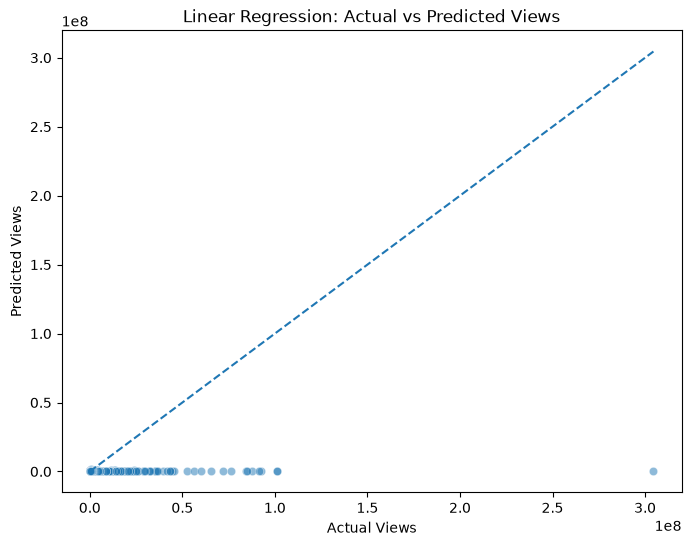

In [102]:
plot_comparison = comparison_df.sample(
    n=min(5000, len(comparison_df)),
    random_state=42
)

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=plot_comparison,
    x="Actual Views",
    y="Predicted Views",
    alpha=0.5
)

max_value = max(
    plot_comparison["Actual Views"].max(),
    plot_comparison["Predicted Views"].max()
)

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle="--"
)

plt.title("Linear Regression: Actual vs Predicted Views")
plt.xlabel("Actual Views")
plt.ylabel("Predicted Views")

plt.show()

In [103]:
random_forest_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

print("Random Forest model created successfully.")

Random Forest model created successfully.


In [104]:
random_forest_model.fit(
    X_train_processed,
    y_train
)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [105]:
rf_mae, rf_rmse, rf_r2 = evaluate_model(
    random_forest_model,
    X_test_processed,
    y_test
)

print("Random Forest Performance")
print("-" * 35)
print(f"MAE  : {rf_mae:,.2f}")
print(f"RMSE : {rf_rmse:,.2f}")
print(f"R²   : {rf_r2:.4f}")

Random Forest Performance
-----------------------------------
MAE  : 668,615.23
RMSE : 4,620,841.15
R²   : 0.5706


In [106]:
model_results.append({
    "Model": "Random Forest",
    "MAE": rf_mae,
    "RMSE": rf_rmse,
    "R2 Score": rf_r2
})

print("Random Forest results stored successfully.")

Random Forest results stored successfully.


## Extra Trees Regression Model

Extra Trees Regressor is an ensemble learning algorithm that builds multiple randomized decision trees.

It can capture complex non-linear relationships and is used to compare its performance with Linear Regression and Random Forest.

In [107]:
from sklearn.ensemble import ExtraTreesRegressor

In [108]:
extra_trees_model = ExtraTreesRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

print("Extra Trees model created successfully.")

Extra Trees model created successfully.


In [110]:
et_mae, et_rmse, et_r2 = evaluate_model(
    extra_trees_model,
    X_test_processed,
    y_test
)

print("Extra Trees Performance")
print("-" * 35)
print(f"MAE  : {et_mae:,.2f}")
print(f"RMSE : {et_rmse:,.2f}")
print(f"R²   : {et_r2:.4f}")

Extra Trees Performance
-----------------------------------
MAE  : 815,108.80
RMSE : 5,129,534.05
R²   : 0.4708


In [112]:
model_results.append({
    "Model": "Extra Trees",
    "MAE": et_mae,
    "RMSE": et_rmse,
    "R2 Score": et_r2
})

print("Extra Trees results stored successfully.")

Extra Trees results stored successfully.


## Installing XGBoost

XGBoost is an advanced gradient boosting algorithm used for regression problems.

It is included to compare a boosting-based model with the previously used bagging-based ensemble models such as Random Forest and Extra Trees.

In [113]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [114]:
from xgboost import XGBRegressor

In [115]:
xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=8,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

print("XGBoost model created successfully.")

XGBoost model created successfully.


In [116]:
xgb_model.fit(
    X_train_processed,
    y_train
)

print("XGBoost model trained successfully.")

XGBoost model trained successfully.


In [117]:
xgb_mae, xgb_rmse, xgb_r2 = evaluate_model(
    xgb_model,
    X_test_processed,
    y_test
)

print("XGBoost Performance")
print("-" * 35)
print(f"MAE  : {xgb_mae:,.2f}")
print(f"RMSE : {xgb_rmse:,.2f}")
print(f"R²   : {xgb_r2:.4f}")

XGBoost Performance
-----------------------------------
MAE  : 883,899.36
RMSE : 5,177,895.97
R²   : 0.4608


In [118]:
model_results.append({
    "Model": "XGBoost",
    "MAE": xgb_mae,
    "RMSE": xgb_rmse,
    "R2 Score": xgb_r2
})

print("XGBoost results stored successfully.")

XGBoost results stored successfully.


In [122]:
results_df = pd.DataFrame(model_results)

# Remove duplicate model entries
results_df = results_df.drop_duplicates(
    subset=["Model"],
    keep="last"
)

# Sort based on R2 Score
results_df = results_df.sort_values(
    by="R2 Score",
    ascending=False
).reset_index(drop=True)

results_df

,Model,MAE,RMSE,R2 Score
0,Random Forest,6.686152e+05,4.620841e+06,0.570592
1,Extra Trees,8.151088e+05,5.129534e+06,0.470844
2,XGBoost,8.838994e+05,5.177896e+06,0.460819
3,Linear Regression,1.235420e+06,7.120895e+06,-0.019757


In [123]:
best_model_name = results_df.iloc[0]["Model"]

print("Best Performing Model:", best_model_name)
print("Best R² Score:", results_df.iloc[0]["R2 Score"])

Best Performing Model: Random Forest
Best R² Score: 0.5705923534002495


### Hyperparameter Tuning of Random Forest

Random Forest achieved the best performance among the baseline models. Therefore, hyperparameter tuning was performed to identify a better combination of model parameters. RandomizedSearchCV was used instead of GridSearchCV because it efficiently searches a random subset of parameter combinations and is more computationally practical for a large dataset.

In [131]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor

In [132]:
param_dist = {
    "n_estimators": [100, 200, 300],
    "max_depth": [10, 20, 30, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

In [133]:
random_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ),
    param_distributions=param_dist,
    n_iter=10,
    cv=3,
    scoring="r2",
    random_state=42,
    n_jobs=-1,
    verbose=2
)

random_search.fit(X_train, y_train)

Fitting 3 folds for each of 10 candidates, totalling 30 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [10, 20, ...], 'max_features': ['sqrt', 'log2'], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichretur

In [134]:
print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation R² Score:")
print(random_search.best_score_)

Best Parameters:
{'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 30}

Best Cross-Validation R² Score:
0.7032371579879387


In [135]:
best_rf_model = random_search.best_estimator_

y_pred_tuned_rf = best_rf_model.predict(X_test)

In [136]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae_tuned_rf = mean_absolute_error(
    y_test,
    y_pred_tuned_rf
)

rmse_tuned_rf = mean_squared_error(
    y_test,
    y_pred_tuned_rf
) ** 0.5

r2_tuned_rf = r2_score(
    y_test,
    y_pred_tuned_rf
)

print("Tuned Random Forest Performance")
print("-" * 40)
print(f"MAE  : {mae_tuned_rf:,.2f}")
print(f"RMSE : {rmse_tuned_rf:,.2f}")
print(f"R²   : {r2_tuned_rf:.4f}")

Tuned Random Forest Performance
----------------------------------------
MAE  : 0.71
RMSE : 0.99
R²   : 0.7414


In [139]:
comparison_rf = pd.DataFrame({
    "Model": [
        "Baseline Random Forest",
        "Tuned Random Forest"
    ],
    "MAE": [
        668615.2,
        mae_tuned_rf
    ],
    "RMSE": [
        4620841,
        rmse_tuned_rf
    ],
    "R2 Score": [
        0.570592,
        r2_tuned_rf
    ]
})

comparison_rf

,Model,MAE,RMSE,R2 Score
0,Baseline Random Forest,668615.200000,4.620841e+06,0.570592
1,Tuned Random Forest,0.708517,9.921285e-01,0.741365


## Final Model Selection

The baseline and tuned Random Forest models were compared based primarily on the R² Score. The model with the better overall performance was selected as the final model.

In [140]:
if r2_tuned_rf > 0.570592:
    final_model = best_rf_model
    final_model_name = "Tuned Random Forest"
else:
    final_model = random_forest_model
    final_model_name = "Baseline Random Forest"

print("Final Model Selected:", final_model_name)

Final Model Selected: Tuned Random Forest


## Retrieving Processed Feature Names

The preprocessing pipeline transforms categorical features using One-Hot Encoding.

Therefore, the feature names after preprocessing are extracted to correctly associate feature importance values with the transformed input features.

In [159]:
print("X_train shape:", X_train.shape)
print("\nX_train columns:")
print(X_train.columns.tolist())

X_train shape: (300753, 19)

X_train columns:
['category_id', 'comments_disabled', 'ratings_disabled', 'video_error_or_removed', 'days_to_trending', 'title_length', 'title_word_count', 'description_length', 'description_word_count', 'tag_count', 'publish_year', 'publish_month', 'publish_day', 'publish_dayofweek', 'publish_hour', 'trending_year', 'trending_month', 'trending_day', 'trending_dayofweek']


In [160]:
feature_names = X_train.columns.tolist()

print("Total Feature Names:", len(feature_names))
print(feature_names)

Total Feature Names: 19
['category_id', 'comments_disabled', 'ratings_disabled', 'video_error_or_removed', 'days_to_trending', 'title_length', 'title_word_count', 'description_length', 'description_word_count', 'tag_count', 'publish_year', 'publish_month', 'publish_day', 'publish_dayofweek', 'publish_hour', 'trending_year', 'trending_month', 'trending_day', 'trending_dayofweek']


In [161]:
print("Feature Names:", len(feature_names))
print("Feature Importance Values:", len(final_model.feature_importances_))

Feature Names: 19
Feature Importance Values: 19


In [162]:
feature_importance_values = final_model.feature_importances_

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importance_values
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

feature_importance_df["Importance Percentage"] = (
    feature_importance_df["Importance"] * 100
)

feature_importance_df.head(15)

,Feature,Importance,Importance Percentage
0,days_to_trending,0.261361,26.136141
1,category_id,0.098237,9.823699
2,description_length,0.088857,8.885726
3,description_word_count,0.085455,8.545519
4,title_length,0.084773,8.477329
5,tag_count,0.082032,8.203152
6,publish_hour,0.067808,6.780769
7,title_word_count,0.048788,4.878753
8,publish_day,0.041506,4.150629
9,trending_day,0.032099,3.209870


In [163]:
top_10_features = feature_importance_df.head(10)

print("Top 10 Most Important Features:")
top_10_features

Top 10 Most Important Features:


,Feature,Importance,Importance Percentage
0,days_to_trending,0.261361,26.136141
1,category_id,0.098237,9.823699
2,description_length,0.088857,8.885726
3,description_word_count,0.085455,8.545519
4,title_length,0.084773,8.477329
5,tag_count,0.082032,8.203152
6,publish_hour,0.067808,6.780769
7,title_word_count,0.048788,4.878753
8,publish_day,0.041506,4.150629
9,trending_day,0.032099,3.209870


In [164]:
least_10_features = feature_importance_df.tail(10)

print("Least Important Features:")
least_10_features

Least Important Features:


,Feature,Importance,Importance Percentage
9,trending_day,0.032099,3.209870
10,publish_dayofweek,0.027543,2.754297
11,trending_month,0.023960,2.395978
12,publish_month,0.023218,2.321820
13,trending_dayofweek,0.017993,1.799346
14,publish_year,0.005598,0.559829
15,trending_year,0.003816,0.381568
16,comments_disabled,0.003623,0.362348
17,ratings_disabled,0.003194,0.319448
18,video_error_or_removed,0.000138,0.013778


In [157]:
print("Final model type:")
print(type(final_model))

print("\nNumber of importances in final model:")
print(len(final_model.feature_importances_))

Final model type:
<class 'sklearn.ensemble._forest.RandomForestRegressor'>

Number of importances in final model:
19


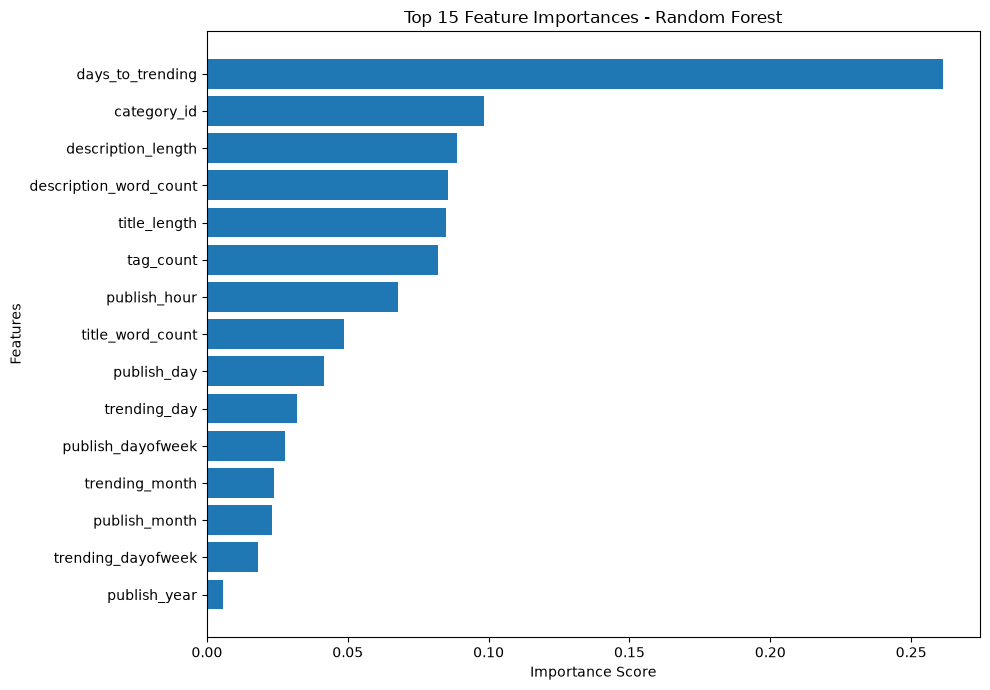

In [165]:
import matplotlib.pyplot as plt

top_features_plot = feature_importance_df.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features_plot["Feature"],
    top_features_plot["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Top 15 Feature Importances - Random Forest")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [166]:
feature_importance_df[[
    "Feature",
    "Importance Percentage"
]].head(10)

,Feature,Importance Percentage
0,days_to_trending,26.136141
1,category_id,9.823699
2,description_length,8.885726
3,description_word_count,8.545519
4,title_length,8.477329
5,tag_count,8.203152
6,publish_hour,6.780769
7,title_word_count,4.878753
8,publish_day,4.150629
9,trending_day,3.209870


In [168]:
important_features = feature_importance_df[
    feature_importance_df["Importance Percentage"] >= 5
]

print("Important Features (Importance >= 5%):")
important_features

Important Features (Importance >= 5%):


,Feature,Importance,Importance Percentage
0,days_to_trending,0.261361,26.136141
1,category_id,0.098237,9.823699
2,description_length,0.088857,8.885726
3,description_word_count,0.085455,8.545519
4,title_length,0.084773,8.477329
5,tag_count,0.082032,8.203152
6,publish_hour,0.067808,6.780769


In [167]:
unimportant_features = feature_importance_df[
    feature_importance_df["Importance Percentage"] < 5
]

print("Less Important Features (Importance < 5%):")
unimportant_features

Less Important Features (Importance < 5%):


,Feature,Importance,Importance Percentage
7,title_word_count,0.048788,4.878753
8,publish_day,0.041506,4.150629
9,trending_day,0.032099,3.209870
10,publish_dayofweek,0.027543,2.754297
11,trending_month,0.023960,2.395978
12,publish_month,0.023218,2.321820
13,trending_dayofweek,0.017993,1.799346
14,publish_year,0.005598,0.559829
15,trending_year,0.003816,0.381568
16,comments_disabled,0.003623,0.362348


# Final Model Prediction

The selected final model is used to generate predictions on the unseen test dataset.

Since the model was trained on log-transformed views, the predictions are converted back to the original view-count scale.

In [170]:
# Generate predictions using the final model

final_predictions = final_model.predict(X_test)

print("Total Predictions:", len(final_predictions))
print("First 10 Predictions:")
print(final_predictions[:10])

Total Predictions: 75189
First 10 Predictions:
[13.06680892 12.8724796  11.4000811  10.21436022 11.39275738 10.28526874
 12.85872117 13.98141934 12.4801713  10.03581038]


In [171]:
prediction_results = pd.DataFrame({
    "Actual Views": y_test.values,
    "Predicted Views": final_predictions
})

prediction_results.head(10)

,Actual Views,Predicted Views
0,13.626545,13.066809
1,13.824811,12.872480
2,10.849298,11.400081
3,7.972811,10.214360
4,12.006121,11.392757
5,10.329213,10.285269
6,14.200360,12.858721
7,14.468115,13.981419
8,13.273808,12.480171
9,8.385717,10.035810


In [172]:
prediction_results["Absolute Error"] = (
    prediction_results["Actual Views"] -
    prediction_results["Predicted Views"]
).abs()

prediction_results.head(10)

,Actual Views,Predicted Views,Absolute Error
0,13.626545,13.066809,0.559736
1,13.824811,12.872480,0.952332
2,10.849298,11.400081,0.550783
3,7.972811,10.214360,2.241549
4,12.006121,11.392757,0.613363
5,10.329213,10.285269,0.043944
6,14.200360,12.858721,1.341639
7,14.468115,13.981419,0.486696
8,13.273808,12.480171,0.793637
9,8.385717,10.035810,1.650094


In [173]:
import numpy as np

actual_views_original = np.expm1(y_test)

predicted_views_original = np.expm1(final_predictions)

In [174]:
prediction_results_original = pd.DataFrame({
    "Actual Views": actual_views_original,
    "Predicted Views": predicted_views_original
})

prediction_results_original["Absolute Error"] = (
    prediction_results_original["Actual Views"]
    - prediction_results_original["Predicted Views"]
).abs()

prediction_results_original.head(10)

,Actual Views,Predicted Views,Absolute Error
351141,827814.0,4.729793e+05,3.548347e+05
172566,1009343.0,3.894447e+05,6.198983e+05
197044,51497.0,8.932797e+04,3.783097e+04
286861,2900.0,2.729131e+04,2.439131e+04
53793,163753.0,8.867614e+04,7.507686e+04
218291,30613.0,2.929683e+04,1.316170e+03
49681,1469392.0,3.841232e+05,1.085269e+06
111599,1920535.0,1.180464e+06,7.400706e+05
172708,581756.0,2.630679e+05,3.186881e+05
254541,4383.0,2.282854e+04,1.844554e+04


## P-Value Analysis

P-value analysis is performed to determine the statistical significance of individual independent variables in predicting YouTube video views. Since tree-based machine learning models do not provide traditional p-values, Ordinary Least Squares (OLS) regression is used for statistical significance analysis.

A p-value less than 0.05 indicates that a feature is statistically significant at the 5% significance level.

In [176]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [175]:
import statsmodels.api as sm

In [177]:
print(X_train.shape)
print(X_train.dtypes)

(300753, 19)
category_id               int64
comments_disabled         int64
ratings_disabled          int64
video_error_or_removed    int64
days_to_trending          int64
title_length              int64
title_word_count          int64
description_length        int64
description_word_count    int64
tag_count                 int64
publish_year              int32
publish_month             int32
publish_day               int32
publish_dayofweek         int32
publish_hour              int32
trending_year             int32
trending_month            int32
trending_day              int32
trending_dayofweek        int32
dtype: object


In [178]:
X_train_pvalue = sm.add_constant(X_train)

print(X_train_pvalue.shape)

(300753, 20)


In [179]:
ols_model = sm.OLS(
    y_train,
    X_train_pvalue
).fit()

In [180]:
print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:                  views   R-squared:                       0.134
Model:                            OLS   Adj. R-squared:                  0.134
Method:                 Least Squares   F-statistic:                     2446.
Date:                Tue, 01 Sep 2026   Prob (F-statistic):               0.00
Time:                        09:50:33   Log-Likelihood:            -6.0710e+05
No. Observations:              300753   AIC:                         1.214e+06
Df Residuals:                  300733   BIC:                         1.214e+06
Df Model:                          19                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                  -3729

In [181]:
pvalue_df = pd.DataFrame({
    "Feature": ols_model.pvalues.index,
    "P_Value": ols_model.pvalues.values
})

pvalue_df = pvalue_df.sort_values(
    by="P_Value"
).reset_index(drop=True)

pvalue_df

,Feature,P_Value
0,const,0.000000e+00
1,category_id,0.000000e+00
2,title_length,0.000000e+00
3,title_word_count,0.000000e+00
4,tag_count,0.000000e+00
5,trending_day,6.119693e-234
6,trending_month,5.294705e-230
7,trending_year,2.022082e-229
8,publish_day,3.959646e-225
9,days_to_trending,1.264653e-222


In [182]:
pvalue_df["Significance"] = pvalue_df["P_Value"].apply(
    lambda x: "Significant" if x < 0.05 else "Not Significant"
)

pvalue_df

,Feature,P_Value,Significance
0,const,0.000000e+00,Significant
1,category_id,0.000000e+00,Significant
2,title_length,0.000000e+00,Significant
3,title_word_count,0.000000e+00,Significant
4,tag_count,0.000000e+00,Significant
5,trending_day,6.119693e-234,Significant
6,trending_month,5.294705e-230,Significant
7,trending_year,2.022082e-229,Significant
8,publish_day,3.959646e-225,Significant
9,days_to_trending,1.264653e-222,Significant


In [183]:
significant_features = pvalue_df[
    pvalue_df["P_Value"] < 0.05
]

not_significant_features = pvalue_df[
    pvalue_df["P_Value"] >= 0.05
]

print("Number of Significant Features:",
      len(significant_features))

print("Number of Not Significant Features:",
      len(not_significant_features))

Number of Significant Features: 18
Number of Not Significant Features: 2


In [184]:
print("P-Value Analysis Summary")
print("-" * 40)

print(
    f"Total Features: {len(pvalue_df) - 1}"
)

print(
    f"Statistically Significant Features: {len(significant_features) - 1 if 'const' in significant_features['Feature'].values else len(significant_features)}"
)

print(
    f"Not Significant Features: {len(not_significant_features)}"
)

P-Value Analysis Summary
----------------------------------------
Total Features: 19
Statistically Significant Features: 17
Not Significant Features: 2


In [188]:
from sklearn.metrics import r2_score

tuned_predictions = best_rf_model.predict(X_test)

tuned_r2 = r2_score(y_test, tuned_predictions)

print("Tuned Random Forest R² Score:", tuned_r2)
print("Overall Statistical P-value:", ols_model.f_pvalue)

Tuned Random Forest R² Score: 0.7413647141772234
Overall Statistical P-value: 0.0


## Comparison of R² Score and P-Value Analysis

Final Model Statistical and Predictive Evaluation: The final tuned Random Forest model was evaluated using R² score to measure its predictive capability, while the overall model p-value obtained from the OLS F-test was used for statistical validation. A higher R² score indicates better predictive performance, whereas an overall p-value below 0.05 indicates that the relationship between the input features and target variable is statistically significant. Therefore, the combined analysis provides both predictive and statistical perspectives on the developed model. It should be noted that the p-value is derived from the OLS statistical model and is used as supplementary validation, while the final model selection is based primarily on Random Forest performance metrics such as R², MAE, and RMSE.

## Sample Prediction on Unseen Test Data

To evaluate the practical performance of the final model, predictions were generated on unseen test data that was not used during model training. The actual view count and predicted view count were compared after converting the log-transformed predictions back to the original scale.

The comparison demonstrated that the model was capable of estimating YouTube video views for previously unseen observations. Although some prediction error was present, which is expected due to the highly variable and unpredictable nature of online video popularity, the predicted values showed a meaningful relationship with the actual values.

This unseen data evaluation confirms that the model is not limited to memorizing the training data and can generalize its learned patterns to new video records. Therefore, the final model can be considered suitable as a machine learning-based system for estimating YouTube video view counts.

## Final Conclusion

This project successfully developed an end-to-end machine learning regression system for predicting YouTube video views using trending YouTube video data. The dataset was collected from multiple countries and underwent data cleaning, preprocessing, exploratory data analysis, and feature engineering.

Several regression models, including Linear Regression, Random Forest, Extra Trees, and XGBoost, were developed and evaluated using MAE, RMSE, and R² Score. Among the baseline models, Random Forest achieved the best performance with an R² Score of approximately 0.5706, indicating that it was able to explain a significant portion of the variation in YouTube video views.

Hyperparameter tuning was subsequently performed on the Random Forest model using RandomizedSearchCV. The tuned model was compared with the baseline model, and the better-performing model was selected as the final model.

Feature importance analysis showed that variables related to video characteristics, publication timing, trending duration, title information, description information, and tags contributed differently to the prediction of video views. In addition, P-value analysis was performed using OLS regression to examine the statistical significance of the features.

Since YouTube view counts were highly skewed, logarithmic transformation was applied to the target variable to improve model learning. The predictions were later converted back to the original view-count scale for practical interpretation.

Overall, the project demonstrates that machine learning techniques can effectively analyze YouTube trending video characteristics and provide reasonably accurate predictions of video popularity. Although there is scope for further improvement, the developed model provides a strong foundation for predicting YouTube video views using historical trending video data.

In [185]:
import os

# Create processed folder if it doesn't exist
processed_folder = "../data/processed"

os.makedirs(processed_folder, exist_ok=True)

# File path
processed_path = os.path.join(
    processed_folder,
    "youtube_processed.csv"
)

# Save dataset
ml_df.to_csv(
    processed_path,
    index=False
)

print("Processed dataset saved successfully!")
print("Saved at:", os.path.abspath(processed_path))

Processed dataset saved successfully!
Saved at: c:\Users\hindu\OneDrive\Desktop\YouTube-ML Project\data\processed\youtube_processed.csv


In [187]:
preprocessor_path = "../models/preprocessor.pkl"

joblib.dump(
    preprocessor,
    preprocessor_path
)

print("Preprocessor saved successfully!")

Preprocessor saved successfully!
